# Two stages, two orders

<div class="alert alert-info">

**Summary**

A consumption stage and a portfolio stage, each written once as a file, form a period in either order; where two stages meet is decided by authored connections and unique compatible inferences between their local fields, not by the order in which a period lists them. In this lesson the reader constructs the four stages of the portfolio–consumption model from their files, forms periods from them, and reads what the package derives from each period: its joins, each a field one stage produces and another stage takes, the order in which its stages are computed, and its drawing. This lesson constructs; it solves nothing.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [The stage as an object](../../getting-started/01-the-stage.ipynb): the consumption stage and its fields.

**Formal account** — [Periods](../../../docs/Bellman-Sym/06-period.md): stage occurrences joined through the fields they share, in the order those fields determine.

**Used by** — [A trellis built backwards](02-a-life-cycle-built-backwards.ipynb), the next lesson of this model, which binds the stages and builds the trellis, and [Solving the two orders](03-solving-the-two-orders.ipynb), which solves both orders.

**See also** — [The portfolio–consumption application](../../../applications/cons-port/README.md): the model's parameter values, methods and numerical tool, which the later lessons read.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[connector]] | A mapping that joins two fields of different names. |
| stage occurrence | One use of a stage at one position of a period. |
| [[trellis]] | A diagram of periods joined by connections, built backwards from the last. |
| inter-period connector | A connector between two consecutive periods. |

</div>

A household consumes out of its resources and divides its savings between a safe asset and a risky one, choosing the share of the risky asset before the risky return and next year's income are drawn. Here a [[period]] is one year, whose [[stage|stages]] are joined by the [[field|fields]] they share.

| In the file | Symbol | Meaning |
|---|---|---|
| `m`, `m_d` | $\mathrm{m}$, $\mathrm{m}_d$ | resources when consumption begins, and at its decision |
| `c` | $\mathrm{c}$ | consumption, chosen in $(0, \mathrm{m}_d]$ |
| `a` | $\mathrm{a}$ | savings at the end of the consumption stage, $\mathrm{a} = \mathrm{m}_d - \mathrm{c}$; the assets discounting arrives at and leaves |
| `k`, `k_d` | $\mathrm{k}$, $\mathrm{k}_d$ | capital when the portfolio stage begins, and at its decision |
| `ς` | $\varsigma$ | the share of capital in the risky asset, chosen in $[0, 1]$ |
| `Ψ`, `θ` | $\Psi$, $\theta$ | the risky gross return and transitory income, drawn after $\varsigma$ is chosen |
| `m_next` | $\mathrm{m}'$ | the resources the portfolio stage produces, for the consumption stage that follows |
| `V`, `D_{x}V` | $V$, $D_x V$ | the value at a perch, and its derivative in a state `x` of the perch, the marginal value |
| `β`, `ρ`, `R` | $\beta$, $\rho$, $R$ | the discount factor (in `disc.bl` alone), relative risk aversion, the safe gross return |

The lesson reads the four stage files of the model, the consumption, portfolio, no-portfolio and discount stages, given here by their paths from the repository root:

- `applications/cons-port/declaration/stages/cons/cons.bl`
- `applications/portfolio-choice/declaration/stages/port/port.bl`
- `applications/portfolio-choice/declaration/stages/noport/noport.bl`
- `applications/portfolio-choice/declaration/stages/disc/disc.bl`

It writes its periods in its own cells, so it reads no trellis file, and it binds no parameter values, methods or settings, so it reads no calibration, methods or settings file. It writes no file. The first code cell imports checkout, the set-up module of the tutorials collection, which the file checkout.py beside this lesson links to: it sets the working directory to the repository root and makes the package importable; it defines one function, explore, which opens the interactive view of a stage or a trellis in Google's Model Explorer and which this lesson does not call. The cell then imports the functions the lesson calls, from bellman.stage, bellman.period and bellman.trellis.

## The household's problem and its timing

The household maximizes the expected sum over the years of $u(\mathrm{c}) = \mathrm{c}^{1-\rho}/(1-\rho)$, each year's utility discounted by $\beta$ (the function `𝑢` of `cons.bl` and the line `V = β*V[>]` of `disc.bl`). It enters the year with resources, consumes, and carries its savings forward. It then divides its capital between a safe asset with gross return $R$ and a risky asset with gross return $\Psi$. The share $\varsigma$ is chosen before $\Psi$ and next year's transitory income $\theta$ are drawn, so the household cannot know the rate of return when it chooses its portfolio. The two draws reach the household only through the resources $\mathrm{m}$ they produce, observed when the next consumption decision is made. If the returns earned in a year belong to that year, the year closes on the resources `m_next` they leave the household with, and the year boundary falls after the portfolio choice, as in the section [Consumption first](#Consumption-first); the section [The portfolio stage first](#The-portfolio-stage-first) draws the boundary before the portfolio choice instead. The model is written as four stage files.

In [1]:
import checkout
from bellman.period import diagram_period, forward_order, period_joins
from bellman.stage import elaborate_stage, load_stage
from bellman.trellis import accrete

## The four stage files

The consumption stage arrives with resources $\mathrm{m}$, chooses $\mathrm{c}$ in $(0, \mathrm{m}_d]$, and continues to savings $\mathrm{a} = \mathrm{m}_d - \mathrm{c}$. It holds no discount factor: discounting is a stage of its own. The next cell prints the file's text from its source record, the dictionary `load_stage` returns (the section [The stage file](../../getting-started/01-the-stage.ipynb#The-stage-file) of the prerequisite lesson).

In [2]:
print(load_stage("applications/cons-port/declaration/stages/cons/cons.bl")["stage"]["text"])

@stage: cons
Xm := ℝ₊₊
Xa := ℝ₊
ρ : (1, inf)
𝑢(c : ℝ₊₊) := c^(1-ρ)/(1-ρ)
Γ(x : ℝ₊₊) := (0, x]

[id=dcsn_to_cntn, (m : Xm, c : ℝ₊₊ @ !ctrl) : !dcsn -> (a : Xa) : !cntn] {
    a = m - c
}

[id=cntn_to_dcsn, (V[>] : ℝ @ !vlu, c) : !cntn -> (V : ℝ @ !vlu) : !dcsn] {
    V = 𝑢(c) + V[>]
}

[id=policy, (V[>]) : !cntn -> (c) : !dcsn] {
    c = argmax_{cp : Γ(m)}(𝑢(cp) + V[>]) :: [id=optimality]
}



The next cell constructs the stage from the file with `elaborate_stage` and names it `cons`.

In [3]:
cons = elaborate_stage(load_stage("applications/cons-port/declaration/stages/cons/cons.bl"))

The next cell lists its fields at the three perches, where ≺ marks arrival, ∼ decision and ≻ continuation.

In [4]:
cons.fields()

cons:dcsn:m   ∼ dcsn  state  in Xm
cons:dcsn:c   ∼ dcsn  control  in ℝ₊₊
cons:cntn:a   ≻ cntn  state  in Xa
cons:cntn:V   ≻ cntn  value  in ℝ
cons:dcsn:V   ∼ dcsn  value  in ℝ

The portfolio stage arrives with capital $\mathrm{k}$ and chooses $\varsigma$. Its two shocks are declared with one joint lognormal distribution and are drawn between the decision and the continuation, marked ∼→≻: the share is chosen knowing capital alone. It continues to next year's resources, $\mathrm{m}' = \mathrm{k}_d(\varsigma\Psi + (1 - \varsigma)R) + \theta$, which the file names `m_next`. The line marked `!doc` states what is maximized; the line under it states the first-order condition, whose zero is the share where it lies in $\Gamma_\varsigma = [0, 1]$; elsewhere the share is at a bound, as the figures of [Solving the two orders](03-solving-the-two-orders.ipynb) show, and the model's tool finds it by a search over $[0, 1]$.

In [5]:
print(load_stage("applications/portfolio-choice/declaration/stages/port/port.bl")["stage"]["text"])

@stage: port

R   : ℝ₊₊
μ_Ψ : ℝ
σ_Ψ : ℝ₊
μ_θ : ℝ
σ_θ : ℝ₊
ρ_ζ : [-1,1]

Γ_ς(k : ℝ₊) := [0,1]

(Ψ : ℝ₊₊, θ : ℝ₊₊)
(Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ),
                   ((σ_Ψ^2,       ρ_ζ*σ_Ψ*σ_θ),
                    (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))

[id=arvl_to_dcsn, (k : ℝ₊) : !arvl -> (k_d : ℝ₊) : !dcsn] {
    k_d = k
}

[id=dcsn_to_cntn, (k_d, ς : !ctrl @ [0,1], Ψ, θ) : !dcsn -> (m_next : ℝ₊₊) : !cntn] {
    m_next = k_d*(ς*Ψ + (1-ς)*R) + θ
}

[id=cntn_to_dcsn, (V[>] : ℝ @ !vlu, ς) : !cntn -> (V : ℝ @ !vlu) : !dcsn] {
    V        = E_{Ψ,θ}(V[>])                            :: [id=value]
    D_{k_d}V = E_{Ψ,θ}(D_{m_next}V[>]*(ς*Ψ + (1-ς)*R))   :: [id=marginal]
}

[id=dcsn_to_arvl, (V) : !dcsn -> (V[<] : ℝ @ !vlu) : !arvl] {
    V[<]  = V                       :: [id=value]
}

[id=policy, (V[>]) : !cntn -> ς] {
    ς = argmax_{ς : Γ_ς(k_d)}(E_{Ψ,θ}(V[>]))    :: [id=objective, !doc]
    ς = solve_{ς}(E_{Ψ,θ}(D_{m_next}V[>]*(Ψ - R)))   :: [id=foc]
}



The next cell constructs the portfolio stage and names it `port`.

In [6]:
port = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/port/port.bl"))

The next cell lists its fields; the two shocks stand between the decision and the continuation, marked ∼→≻.

In [7]:
port.fields()

port:arvl:k        ≺ arvl  state  in ℝ₊
port:dcsn:k_d      ∼ dcsn  state  in ℝ₊
port:dcsn:ς        ∼ dcsn  control  in [0, 1]
port:shck:Ψ        ∼→≻  shock  in ℝ₊₊
port:shck:θ        ∼→≻  shock  in ℝ₊₊
port:cntn:m_next   ≻ cntn  state  in ℝ₊₊
port:cntn:V        ≻ cntn  value  in ℝ
port:dcsn:V        ∼ dcsn  value  in ℝ
port:arvl:V        ≺ arvl  value  in ℝ

The stage without a portfolio choice draws income and continues to $\mathrm{m} = \mathrm{k}_d R + \theta$; it chooses nothing. The next cell constructs it and names it `noport`.

In [8]:
noport = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/noport/noport.bl"))

The next cell lists its fields: capital at arrival and at the decision, income drawn after the decision, and resources `m` at the continuation.

In [9]:
noport.fields()

noport:arvl:k     ≺ arvl  state  in Xk
noport:dcsn:k_d   ∼ dcsn  state  in Xk
noport:shck:θ     ∼→≻  shock  in Θ
noport:cntn:m     ≻ cntn  state  in Xm
noport:cntn:V     ≻ cntn  value  in ℝ
noport:dcsn:V     ∼ dcsn  value  in ℝ
noport:arvl:V     ≺ arvl  value  in ℝ

The discount stage multiplies the value by $\beta$ and passes savings through; it is the only stage file that declares $\beta$. The next cell constructs it and names it `disc`.

In [10]:
disc = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/disc/disc.bl"))

The next cell lists its fields: savings at each of the three perches.

In [11]:
disc.fields()

disc:arvl:a     ≺ arvl  state  in Xa
disc:dcsn:a_d   ∼ dcsn  state  in Xa
disc:cntn:a     ≻ cntn  state  in Xa
disc:cntn:V     ≻ cntn  value  in ℝ
disc:dcsn:V     ∼ dcsn  value  in ℝ
disc:arvl:V     ≺ arvl  value  in ℝ

A stage displays its name and its version: `symbolic` until it is calibrated, methodized and configured, that is, bound to its parameter values, its numerical methods and its numerical settings, such as the sizes of its grids. The next lesson of this model, [A trellis built backwards](02-a-life-cycle-built-backwards.ipynb), binds them.

In [12]:
cons, port, noport, disc

(ElaboratedStage('cons', symbolic),
 ElaboratedStage('port', symbolic),
 ElaboratedStage('noport', symbolic),
 ElaboratedStage('disc', symbolic))

## The portfolio stage first

A period is a set of stage occurrences, each one use of a stage at one position, and the selected connections between their local fields. The position is an address, not an input to a stage. Repeated declarations in a [modular model](../../../docs/bellman-calculus/APPX-H-MODULARITY.md) retain their operators and calibration sources; their supplied fields, methods and settings may differ. The period is written as a dictionary of stages and a list of connectors. The package infers an equal-name connection only when it is uniquely compatible and creates no cycle. A **connector** is a mapping `{continuation field: arrival field}` that explicitly connects two occurrences without changing their local names. Here `{m_next: m}` connects the portfolio stage's continuation resources to consumption's arrival resources; savings join the discount stage by inference; the discount stage's `a` leaves the period. Both endpoints of the written connector are unique, so neither needs a stage prefix. The next cell names this portfolio-first period `beginning`; the period under [Consumption first](#Consumption-first) is named `end`.

In [13]:
beginning = {"stages": {"port": port, "cons": cons, "disc": disc}, "connectors": [{"m_next": "m"}]}

`period_joins` gives the joins the package derives, each from a continuation field of one stage to an arrival field of another, and the outputs, the continuation fields no stage of the period takes.

In [14]:
period_joins(beginning)

{'joins': [{'from': ('cons', 'a'), 'to': ('disc', 'a')},
  {'from': ('port', 'm_next'), 'to': ('cons', 'm')}],
 'outputs': [('disc', 'a')]}

The order in which the stages are computed follows from the joins.

In [15]:
forward_order(beginning)

['port', 'cons', 'disc']

A period is drawn as a period of a [[trellis]], a diagram of periods joined by connections, represented as a dictionary of two lists: `periods`, and `inter_connectors`, the connectors between consecutive periods. `accrete` appends a period to a trellis; appended to the empty trellis, `{"periods": [], "inter_connectors": []}`, the period is the only one and stands at index 0, the index of a trellis's last period. `diagram_period` draws the period at an index under the title `periods[0]`, the period's address: one box per stage in the computation order, one arrow per join labeled with the field it carries, `m_next → m` for that authored connection, and the field that leaves the period at the right.

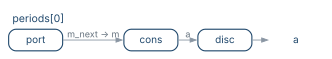

In [16]:
diagram_period(accrete({"periods": [], "inter_connectors": []}, beginning), 0)

## Consumption first

The same three files, listed in another order, with the connector `{disc.a: k}`. Both `cons` and `disc` continue to a local field `a`, so the source needs its stage key. The destination `k` is unique and stays bare. The consumption stage ends in savings $\mathrm{a}$, which the discount stage passes on, and the connector makes the discount stage's assets the portfolio stage's capital $\mathrm{k}$. The portfolio stage's `m_next` now leaves the period; next year's consumption stage will arrive at it. The year begins with observed resources and ends with next year's resources: the returns of a year are earned inside it. The next cell writes this period and names it `end`.

In [17]:
end = {"stages": {"cons": cons, "disc": disc, "port": port}, "connectors": [{"disc.a": "k"}]}

Its joins: savings join the discount stage by name, and the connector joins the discount stage's assets to the portfolio stage's capital.

In [18]:
period_joins(end)

{'joins': [{'from': ('cons', 'a'), 'to': ('disc', 'a')},
  {'from': ('disc', 'a'), 'to': ('port', 'k')}],
 'outputs': [('port', 'm_next')]}

The order follows from these joins.

In [19]:
forward_order(end)

['cons', 'disc', 'port']

The next cell lists the same period's stages the other way round and finds the same order; the order in which the dictionary lists the stages carries no meaning.

In [20]:
forward_order({"stages": {"port": port, "disc": disc, "cons": cons}, "connectors": [{"disc.a": "k"}]})

['cons', 'disc', 'port']

The next cell draws the period as the portfolio-first period was drawn.

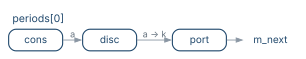

In [21]:
diagram_period(accrete({"periods": [], "inter_connectors": []}, end), 0)

## No portfolio, then consumption

With the stage without a portfolio choice before consumption the names match: it continues to `m` and consumption arrives at `m`, so no connector is needed. The next cell writes this period and names it `cons_only`.

In [22]:
cons_only = {"stages": {"noport": noport, "cons": cons, "disc": disc}, "connectors": []}

The next cell gives the order in which its stages are computed.

In [23]:
forward_order(cons_only)

['noport', 'cons', 'disc']

Its joins; savings leave through the discount stage as before.

In [24]:
period_joins(cons_only)

{'joins': [{'from': ('cons', 'a'), 'to': ('disc', 'a')},
  {'from': ('noport', 'm'), 'to': ('cons', 'm')}],
 'outputs': [('disc', 'a')]}

## Authored connections must not form a cycle

The stage without a portfolio choice keeps the name `m`. The next cell explicitly connects consumption's savings to discounting, the discounted savings to the no-portfolio stage, and that stage's resources back to consumption. These three authored arrows close a cycle between stages, which the package refuses. This is different from reusing a local name or crossing two field pairs between the same two stages. Inference leaves a cyclic set of candidate arrows unresolved rather than choosing an order. The separate name `m_next` makes the portfolio example's timing visible; it is not a requirement that every stage use different names. The second argument of `forward_order` gives the period's address in the refusal.

In [25]:
forward_order({"stages": {"cons": cons, "disc": disc, "noport": noport}, "connectors": [{"cons.a": "a", "disc.a": "k", "m": "m"}]}, "periods[0]")

FactoryError: address 'periods[0]': the joins of the period form a cycle: cons continues to 'a' and disc arrives at 'a'; disc continues to 'a' and noport arrives at 'k'; noport continues to 'm' and cons arrives at 'm'; the stages of a period are ordered by their field dependencies, so no stage may take a field it produces through the others; write connectors with no cycle among the stages; remove or redirect an authored connector, and qualify an endpoint with its stage key where its bare name is ambiguous (rule period-join-cycle)

## The portfolio stage alone

The portfolio stage alone is a problem in which all resources are invested: the connector `{m_next: a}` gives its output to the discount stage as its assets. The next cell writes this period and names it `port_only`.

In [26]:
port_only = {"stages": {"port": port, "disc": disc}, "connectors": [{"m_next": "a"}]}

The next cell gives the order in which its stages are computed.

In [27]:
forward_order(port_only)

['port', 'disc']

Its joins; the discount stage's assets leave the period.

In [28]:
period_joins(port_only)

{'joins': [{'from': ('port', 'm_next'), 'to': ('disc', 'a')}],
 'outputs': [('disc', 'a')]}

## One mapping in two places

Across a year boundary, `inter_connectors[h]` joins the continuation fields that leave period $h + 1$ to the arrival fields of period $h$, where $h$ counts periods back from the last, $h = 0$; this mapping is the inter-period connector. The mapping `{m_next: m}` joins the portfolio stage to consumption inside a period in the first order and joins one year to the next in the second; `{disc.a: k}` does the reverse. A connector and an inter-period connector are one kind of object, differing only in the join they occupy. The next lesson of this model, [A trellis built backwards](02-a-life-cycle-built-backwards.ipynb), builds that join.